In [1]:
import logging

import numpy as np
import optimistix as optx
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    Species,
    SpeciesCollection,
    debug_logger,
)
from atmodeller.eos import get_eos_models
from atmodeller.solubility import get_solubility_models
from atmodeller.thermodata import IronWustiteBuffer

logger = debug_logger()
logger.setLevel(logging.INFO)
# For more output use DEBUG
# logger.setLevel(logging.DEBUG)

Atmodeller initialized with double precision (float64)


# Sub-Neptune (e.g. K2-18b) models from Bower et al. (2025)

The code blocks below must always be run, but then you can preferentially run only the models for ideal or real gases.

Parameters for the simulations

In [2]:
number_of_realisations = 10
surface_temperature = 3000  # K

# For simulations with fixed mass and surface radius:
planet_mass = 5.154e25 
surface_radius = 1.1225e7  # using M-R relation from Hakim+2018
mantle_melt_fraction = 1  # 0.1

RANDOM_SEED = 0
np.random.seed(RANDOM_SEED)

In [3]:
solubility_models = get_solubility_models()

H2O_g = Species.create_gas("H2O", solubility=solubility_models["H2O_basalt_dixon95"])
H2_g = Species.create_gas("H2", solubility=solubility_models["H2_basalt_hirschmann12"])
O2_g = Species.create_gas("O2")
CO_g = Species.create_gas("CO", solubility=solubility_models["CO_basalt_yoshioka19"])
CO2_g = Species.create_gas("CO2", solubility=solubility_models["CO2_basalt_dixon95"])
CH4_g = Species.create_gas("CH4", solubility=solubility_models["CH4_basalt_ardia13"])

idealspecies_withsols = SpeciesCollection((H2O_g, H2_g, O2_g, CO_g, CO2_g, CH4_g))

In [4]:
eos_models = get_eos_models()

H2O_rg = Species.create_gas(
    "H2O",
    activity=eos_models["H2O_cork_holland98"],
    solubility=solubility_models["H2O_basalt_dixon95"],
)
H2_rg = Species.create_gas(
    "H2",
    activity=eos_models["H2_chabrier21"],
    solubility=solubility_models["H2_basalt_hirschmann12"],
)
O2_rg = Species.create_gas("O2", activity=eos_models["O2_cs_shi92"])
CO_rg = Species.create_gas(
    "CO",
    activity=eos_models["CO_cs_shi92"],
    solubility=solubility_models["CO_basalt_yoshioka19"],
)
CO2_rg = Species.create_gas(
    "CO2",
    activity=eos_models["CO2_cs_shi92"],
    solubility=solubility_models["CO2_basalt_dixon95"],
)
CH4_rg = Species.create_gas(
    "CH4",
    activity=eos_models["CH4_cs_shi92"],
    solubility=solubility_models["CH4_basalt_ardia13"],
)

realspecies_withsols = SpeciesCollection((H2O_rg, H2_rg, O2_rg, CO_rg, CO2_rg, CH4_rg))


## Hydrogen fraction

Where does saturation occur

In [5]:
# Vary Linearly:

def vary_HF():
    log10_H_frac = np.linspace(-6, 2, number_of_realisations)

    # Fix Values for Linearly Varying Cases:
    log10_ch_ratios = np.full(number_of_realisations, -0.5)  # 100X Solar
    fO2_log10_shifts = np.full(number_of_realisations, -3)

    h_kg = ((10**log10_H_frac) / 100) * planet_mass
    c_kg = h_kg * 10**log10_ch_ratios

    mass_constraints = {
        "H": h_kg,
        "C": c_kg,
    }

    lijstje = []
    lijstje.append(mass_constraints)
    lijstje.append(fO2_log10_shifts)
    
    return lijstje


In [6]:
def make_planet(surface_temperature, planet_mass, surface_radius, mantle_melt_fraction):
    sub_neptune = Planet(
        surface_temperature=surface_temperature,
        planet_mass=planet_mass,
        surface_radius=surface_radius,
        mantle_melt_fraction=mantle_melt_fraction,
    )
    return sub_neptune

In [7]:
def solve_the_model(sub_neptune, H_RESULTS, species):

    mass_constraints = H_RESULTS[0]
    fO2_log10_shifts = H_RESULTS[1]
    
    solver = optx.LevenbergMarquardt
    solver_parameters = SolverParameters(solver=solver)
    
    model_ideal_varyHF_withsol = InteriorAtmosphere(species)
    
    fugacity_constraints = {O2_g.name: IronWustiteBuffer(fO2_log10_shifts)}
    
    model_ideal_varyHF_withsol.solve(
        planet=sub_neptune,
        mass_constraints=mass_constraints,
        fugacity_constraints=fugacity_constraints,
        solver_parameters=solver_parameters,
    )
    output_ideal_varyHF_withsol = model_ideal_varyHF_withsol.output
    
    # Write the complete solution to Excel
    file = output_ideal_varyHF_withsol.to_excel("FILE2")
    
    # Write the data to a pickle file with dataframes
    output_ideal_varyHF_withsol.to_pickle("FILE2")

    return file

In [8]:
def calculate_values(file, real=True):
    
    file = 'FILE2.xlsx'
    
    # === Load sheets ===
    planet = pd.read_excel(file, sheet_name='planet')
    atmosphere = pd.read_excel(file, sheet_name='atmosphere')
    element_H = pd.read_excel(file, sheet_name='element_H')
    element_C = pd.read_excel(file, sheet_name='element_C')
    element_O = pd.read_excel(file, sheet_name='element_O')
    molecule_CO2 = pd.read_excel(file, sheet_name='CO2_g')
    molecule_CO = pd.read_excel(file, sheet_name='CO_g')
    molecule_H2 = pd.read_excel(file, sheet_name='H2_g')
    molecule_CH4 = pd.read_excel(file, sheet_name='CH4_g')
    molecule_H2O = pd.read_excel(file, sheet_name='H2O_g')

    lijst = []

    # 1. Hydrogen fraction (dissolved / total)
    H_diss = element_H['dissolved_moles']
    H_total = element_H['total_moles']
    H_frac = H_diss / H_total
    lijst.append(H_frac)

    # 2. C/O ratio
    C_moles = element_C['atmosphere_moles']
    O_moles = element_O['atmosphere_moles']
    C_O_ratio = C_moles / O_moles
    lijst.append(C_O_ratio)

    # 3. CO₂/CO ratio
    CO2_moles = molecule_CO2['atmosphere_moles']
    CO_moles = molecule_CO['atmosphere_moles']
    CO_CO2_ratio = CO_moles / CO2_moles
    lijst.append(CO_CO2_ratio)

    # 4. CH₄/CO₂ ratio
    CH4_moles = molecule_CH4['atmosphere_moles']
    CH4_CO2_ratio = CH4_moles / CO2_moles
    lijst.append(CH4_CO2_ratio)

    # 5. H₂ dissolved fraction
    H2_diss = molecule_H2['dissolved_moles']
    H2_total = molecule_H2['total_moles']
    H2_frac = H2_diss / H2_total
    lijst.append(H2_frac)

    # 6. Fugacity H₂
    if real and 'fugacity' in molecule_H2.columns:
        fugacity = molecule_H2['fugacity']
        lijst.append(fugacity)

    # 7. Add H₂_diss directly
    H2_atm = molecule_H2['atmosphere_moles']
    surface_pressure = atmosphere['pressure']
    lijst.append([H2_diss, H2_atm, H2_total, surface_pressure])
    
    # 8. Rate of change in dissolved ppmw
    total_mass = molecule_H2['total_mass']

    # Finite differences for derivative
    dH2_diss = np.gradient(H2_diss)
    dmass = np.gradient(total_mass)
    rate_change_ppmw = dH2_diss / dmass
    lijst.append(rate_change_ppmw)

    H2O_total_mass = molecule_H2O['total_mass']
    H2_total_mass = molecule_H2['total_mass']
    H2O_H2_ratio = H2O_total_mass / H2_total_mass
    lijst.append(H2O_H2_ratio)

    H2O_dissolved_mass = molecule_H2O['dissolved_mass']
    H2O_total_mass = H2O_total_mass = molecule_H2O['total_mass']
    H2O_diss_frac = H2O_dissolved_mass / H2O_total_mass
    lijst.append(H2O_diss_frac)

    H_dissolved_mass = element_H['dissolved_mass']
    planet_mass = planet['planet_mass']
    H_dissolved_rel_to_PM = H_dissolved_mass / planet_mass
    lijst.append(H_dissolved_rel_to_PM)

    C_dissolved_mass = element_C['dissolved_mass']
    planet_mass = planet['planet_mass']
    C_dissolved_rel_to_PM = C_dissolved_mass / planet_mass
    lijst.append(C_dissolved_rel_to_PM)
    
    return lijst

In [9]:
def saturation_calculator(H_RESULTS, planet_mass, y):
    
    mass_constraints = H_RESULTS[0]
    h_kg = np.array(mass_constraints['H'])

    x = h_kg / planet_mass
    sat_x, oversat_x, y_min = None, None, None

    # Saturation: first point where y < 0.98
    sat_candidates = np.where(y < 0.995)[0]
    if len(sat_candidates) > 0:
        sat_x = x[sat_candidates[0]]

    # Oversaturation: minimum of y
    y_min = min(y)
    oversat_x = x[np.argmin(y)]

    return sat_x, oversat_x, y_min


In [20]:
def mass_calculator(radius):
    radiusV = radius / 6378137
    masslist = []
    if radiusV < 2:
        mass_ratio = 0.98 * radiusV**3.57
        mass = 5.97219e24 * mass_ratio
        masslist.append(mass)
        MASS = masslist[0]
        print(MASS)
    elif radiusV >= 2:
        mass_ratio = 1.64 * radiusV**1.49
        mass = 5.97219e24 * mass_ratio
        masslist.append(mass)
        MASS = masslist[0]
        print(MASS)
    return MASS

In [11]:
def saturation_points(parameter, parameter_range, rest, species, real):

    H_range = vary_HF()
    sat_points = [[], [], []]     # Always initialize

    if parameter == 'TEMPERATURE':
        radius = 1
        mantle = 1
        mass = mass_calculator(radius)

    elif parameter == 'MASS':
        radius = 1
        mantle = 1
        mass = mass_calculator(radius)

    elif parameter == 'RADIUS':
        temperature = 3000
        mantle = 1
        rad = 6378137   # Earth radius

        for i in parameter_range:
            radius = rad * i
            mass = mass_calculator(radius)

            sub_neptune = make_planet(temperature, mass, radius, mantle)
            solved_model = solve_the_model(sub_neptune, H_range, species)
            values = calculate_values(solved_model, real)

            # CORRECT: planet_mass was undefined
            sat_x, oversat_x, y_min = saturation_calculator(H_range, mass, values[0])

            sat_points[0].append(sat_x)
            sat_points[1].append(oversat_x)
            sat_points[2].append(y_min)

    elif parameter == 'MANTLE':
        radius = 1
        mantle = 1
        mass = mass_calculator(radius)

    return plot_saturation_points(sat_points, parameter_range)


In [12]:
def plot_saturation_points(points, parRange):

    # Separate points
    sat_points = points[0]
    oversat_points = points[1]
    y_minima = points[2]

    # Saturation scatter plot
    plt.figure(figsize=(8, 4))
    plt.scatter(parRange, sat_points, color='purple', label='Saturation', s=70)
    plt.xlabel('Parameter')
    plt.ylabel('Saturation Point')
    plt.title('Saturation Points vs Parameter')
    plt.grid(True)
    plt.legend()
    plt.show()

    # Oversaturation scatter plot
    plt.figure(figsize=(8, 4))
    plt.scatter(parRange, oversat_points, color='pink', label='Oversaturation', s=70)
    plt.xlabel('Parameter')
    plt.ylabel('Oversaturation Point')
    plt.title('Oversaturation Points vs Parameter')
    plt.grid(True)
    plt.legend()
    plt.show()

    plt.figure(figsize=(8, 4))
    plt.scatter(parRange, y_minima, color='orange', label='minima', s=70)
    plt.xlabel('Parameter')
    plt.ylabel('Minima')
    plt.title('Minima vs Parameter')
    plt.grid(True)
    plt.legend()
    plt.show()

    plt.figure(figsize=(8, 4))
    plt.plot(parRange, sat_points, 'o-', lw=2, ms=1, color='tab:blue', label='saturation')
    plt.plot(parRange, oversat_points, 's-', lw=2, ms=1, color='tab:orange', label='oversaturation')
    plt.xlabel('Parameter')
    plt.ylabel('Oversaturation and saturation points')
    plt.title('Oversaturation  and Saturation Points vs Parameter')
    plt.grid(True)
    plt.legend()
    plt.show()



In [13]:
def FUNTION_RUNNER(parameter_to_vary, parameter_range, rest, species, real):
    return saturation_points(parameter_to_vary, parameter_range, rest, species, real)
        

In [14]:
miauw = [1.000, 1.030, 1.061, 1.091, 1.121, 1.152, 1.182, 1.212, 1.242, 1.273,
 1.303, 1.333, 1.364, 1.394, 1.424, 1.455, 1.485, 1.515, 1.545, 1.576,
 1.606, 1.636, 1.667, 1.697, 1.727, 1.758, 1.788, 1.818, 1.848, 1.879,
 1.909, 1.939, 1.970, 2.000, 2.030, 2.061, 2.091, 2.121, 2.152, 2.182,
 2.212, 2.242, 2.273, 2.303, 2.333, 2.364, 2.394, 2.424, 2.455, 2.485,
 2.515, 2.545, 2.576, 2.606, 2.636, 2.667, 2.697, 2.727, 2.758, 2.788,
 2.818, 2.848, 2.879, 2.909, 2.939, 2.970, 3.000, 3.030, 3.061, 3.091,
 3.121, 3.152, 3.182, 3.212, 3.242, 3.273, 3.303, 3.333, 3.364, 3.394,
 3.424, 3.455, 3.485, 3.515, 3.545, 3.576, 3.606, 3.636, 3.667, 3.697,
 3.727, 3.758, 3.788, 3.818, 3.848, 3.879, 3.909, 3.939, 3.970, 4.000]

[21:07:56 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13')
[21:07:56 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[21:07:56 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2_g + 0.5 O2_g = 1.0 H2O_g',
 1: '0.5 O2_g + 1.0 CO_g = 1.0 CO2_g',
 2: '2.0 H2_g + 1.0 CO_g = 0.5 O2_g + 1.0 CH4_g'}
[21:07:56 - atmodeller.classes             - INFO     ] - Attempting to solve 10 model(s)


8.361066000000001e+24


[21:07:57 - atmodeller.classes             - INFO     ] - Solve complete: 10 (100.00%) successful model(s)
[21:07:57 - atmodeller.classes             - INFO     ] - Solver steps (max) = 162
[21:07:57 - atmodeller.output              - INFO     ] - Writing output to excel
[21:07:57 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[21:07:57 - atmodeller.output_core         - INFO     ] - Computing asdict output
[21:07:57 - atmodeller.output              - INFO     ] - Output written to FILE2.xlsx
[21:07:57 - atmodeller.output              - INFO     ] - Writing output to pickle
[21:07:57 - atmodeller.output              - INFO     ] - Output written to FILE2.pkl
[21:07:57 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'C

8.949262942344598e+24


[21:07:58 - atmodeller.classes             - INFO     ] - Solve complete: 10 (100.00%) successful model(s)
[21:07:58 - atmodeller.classes             - INFO     ] - Solver steps (max) = 160
[21:07:58 - atmodeller.output              - INFO     ] - Writing output to excel
[21:07:58 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[21:07:58 - atmodeller.output_core         - INFO     ] - Computing asdict output
[21:07:58 - atmodeller.output              - INFO     ] - Output written to FILE2.xlsx
[21:07:58 - atmodeller.output              - INFO     ] - Writing output to pickle
[21:07:58 - atmodeller.output              - INFO     ] - Output written to FILE2.pkl
[21:07:58 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'C

...

[21:09:18 - atmodeller.classes             - INFO     ] - Solve complete: 10 (100.00%) successful model(s)
[21:09:18 - atmodeller.classes             - INFO     ] - Solver steps (max) = 84
[21:09:18 - atmodeller.output              - INFO     ] - Writing output to excel
[21:09:18 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[21:09:18 - atmodeller.output_core         - INFO     ] - Computing asdict output
[21:09:19 - atmodeller.output              - INFO     ] - Output written to FILE2.xlsx
[21:09:19 - atmodeller.output              - INFO     ] - Writing output to pickle
[21:09:19 - atmodeller.output              - INFO     ] - Output written to FILE2.pkl
[21:09:19 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CH

1.9928738899765422e+26


[21:09:19 - atmodeller.classes             - INFO     ] - Solve complete: 10 (100.00%) successful model(s)
[21:09:19 - atmodeller.classes             - INFO     ] - Solver steps (max) = 77
[21:09:19 - atmodeller.output              - INFO     ] - Writing output to excel
[21:09:19 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[21:09:19 - atmodeller.output_core         - INFO     ] - Computing asdict output
[21:09:19 - atmodeller.output              - INFO     ] - Output written to FILE2.xlsx
[21:09:19 - atmodeller.output              - INFO     ] - Writing output to pickle
[21:09:19 - atmodeller.output              - INFO     ] - Output written to FILE2.pkl
[21:09:20 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CH

2.027680999981892e+26


[21:09:20 - atmodeller.classes             - INFO     ] - Solve complete: 10 (100.00%) successful model(s)
[21:09:20 - atmodeller.classes             - INFO     ] - Solver steps (max) = 73
[21:09:20 - atmodeller.output              - INFO     ] - Writing output to excel
[21:09:20 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[21:09:20 - atmodeller.output_core         - INFO     ] - Computing asdict output
[21:09:20 - atmodeller.output              - INFO     ] - Output written to FILE2.xlsx
[21:09:20 - atmodeller.output              - INFO     ] - Writing output to pickle
[21:09:20 - atmodeller.output              - INFO     ] - Output written to FILE2.pkl


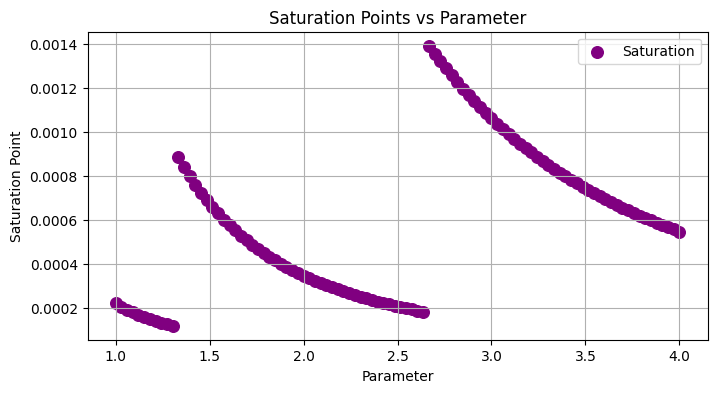

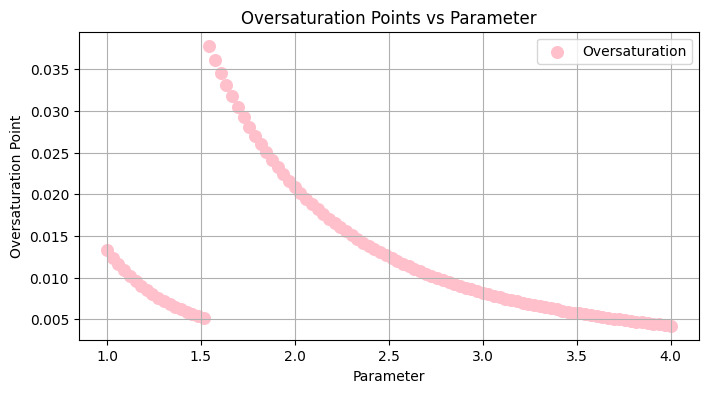

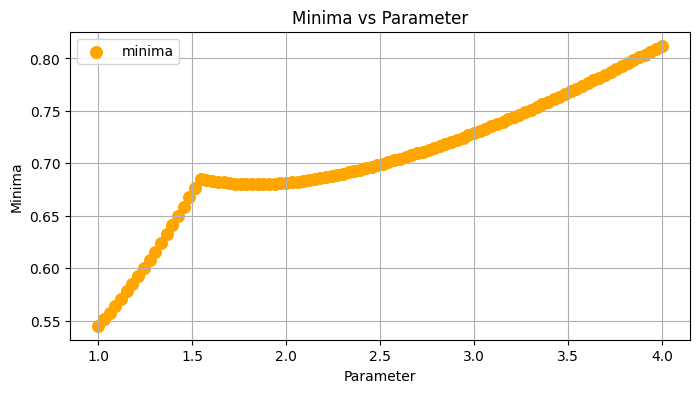

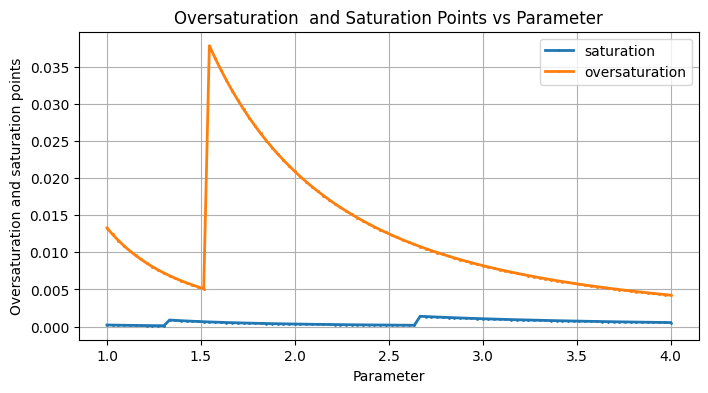

In [58]:
FUNTION_RUNNER('RADIUS', miauw, [], realspecies_withsols, True)

[12:50:36 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13')
[12:50:36 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[12:50:36 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2_g + 0.5 O2_g = 1.0 H2O_g',
 1: '0.5 O2_g + 1.0 CO_g = 1.0 CO2_g',
 2: '2.0 H2_g + 1.0 CO_g = 0.5 O2_g + 1.0 CH4_g'}
[12:50:36 - atmodeller.classes             - INFO     ] - Attempting to solve 10 model(s)


1.6124913000000003e+25


[12:50:59 - atmodeller.classes             - INFO     ] - Solve complete: 10 (100.00%) successful model(s)
[12:50:59 - atmodeller.classes             - INFO     ] - Solver steps (max) = 147
[12:50:59 - atmodeller.output              - INFO     ] - Writing output to excel
[12:50:59 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[12:50:59 - atmodeller.output_core         - INFO     ] - Computing asdict output
[12:51:03 - atmodeller.output              - INFO     ] - Output written to FILE2.xlsx
[12:51:03 - atmodeller.output              - INFO     ] - Writing output to pickle
[12:51:03 - atmodeller.output              - INFO     ] - Output written to FILE2.pkl
[12:51:03 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'C

1.6756594968329001e+25


[12:51:03 - atmodeller.classes             - INFO     ] - Solve complete: 10 (100.00%) successful model(s)
[12:51:03 - atmodeller.classes             - INFO     ] - Solver steps (max) = 145
[12:51:04 - atmodeller.output              - INFO     ] - Writing output to excel
[12:51:04 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[12:51:04 - atmodeller.output_core         - INFO     ] - Computing asdict output
[12:51:04 - atmodeller.output              - INFO     ] - Output written to FILE2.xlsx
[12:51:04 - atmodeller.output              - INFO     ] - Writing output to pickle
[12:51:04 - atmodeller.output              - INFO     ] - Output written to FILE2.pkl
[12:51:04 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'C

...

[12:52:25 - atmodeller.classes             - INFO     ] - Solve complete: 10 (100.00%) successful model(s)
[12:52:25 - atmodeller.classes             - INFO     ] - Solver steps (max) = 70
[12:52:25 - atmodeller.output              - INFO     ] - Writing output to excel
[12:52:25 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[12:52:25 - atmodeller.output_core         - INFO     ] - Computing asdict output
[12:52:26 - atmodeller.output              - INFO     ] - Output written to FILE2.xlsx
[12:52:26 - atmodeller.output              - INFO     ] - Writing output to pickle
[12:52:26 - atmodeller.output              - INFO     ] - Output written to FILE2.pkl
[12:52:26 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CH

9.68110741802207e+25


[12:52:26 - atmodeller.classes             - INFO     ] - Solve complete: 10 (100.00%) successful model(s)
[12:52:26 - atmodeller.classes             - INFO     ] - Solver steps (max) = 69
[12:52:26 - atmodeller.output              - INFO     ] - Writing output to excel
[12:52:26 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[12:52:26 - atmodeller.output_core         - INFO     ] - Computing asdict output
[12:52:26 - atmodeller.output              - INFO     ] - Output written to FILE2.xlsx
[12:52:26 - atmodeller.output              - INFO     ] - Writing output to pickle
[12:52:26 - atmodeller.output              - INFO     ] - Output written to FILE2.pkl
[12:52:27 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CH

9.776319107055555e+25


[12:52:27 - atmodeller.classes             - INFO     ] - Solve complete: 10 (100.00%) successful model(s)
[12:52:27 - atmodeller.classes             - INFO     ] - Solver steps (max) = 66
[12:52:27 - atmodeller.output              - INFO     ] - Writing output to excel
[12:52:27 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[12:52:27 - atmodeller.output_core         - INFO     ] - Computing asdict output
[12:52:27 - atmodeller.output              - INFO     ] - Output written to FILE2.xlsx
[12:52:27 - atmodeller.output              - INFO     ] - Writing output to pickle
[12:52:27 - atmodeller.output              - INFO     ] - Output written to FILE2.pkl


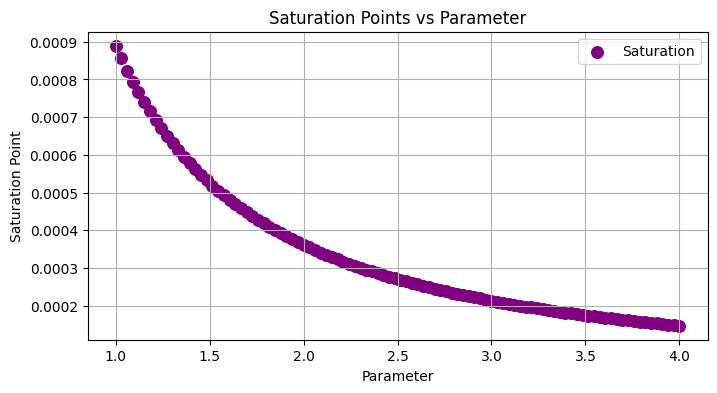

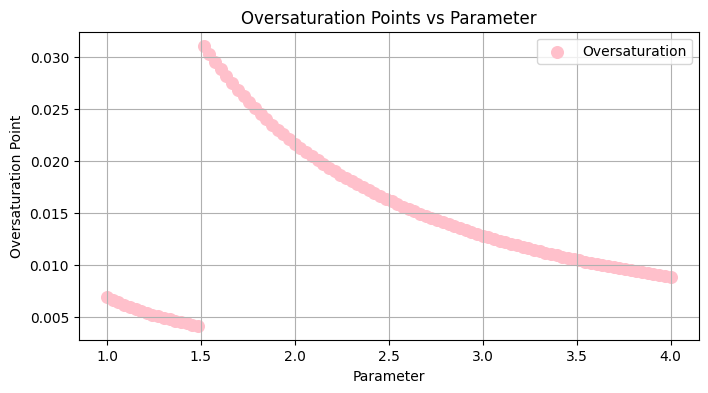

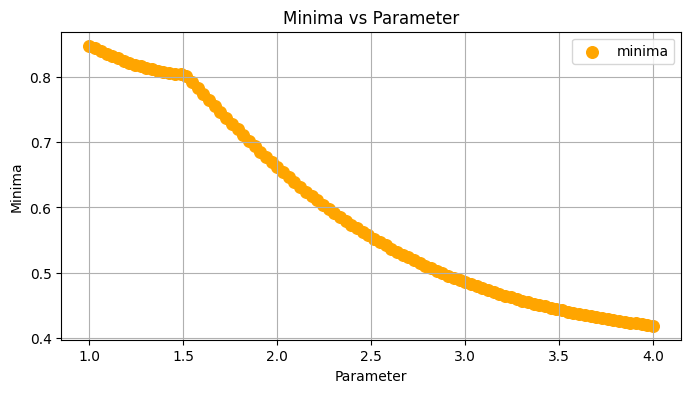

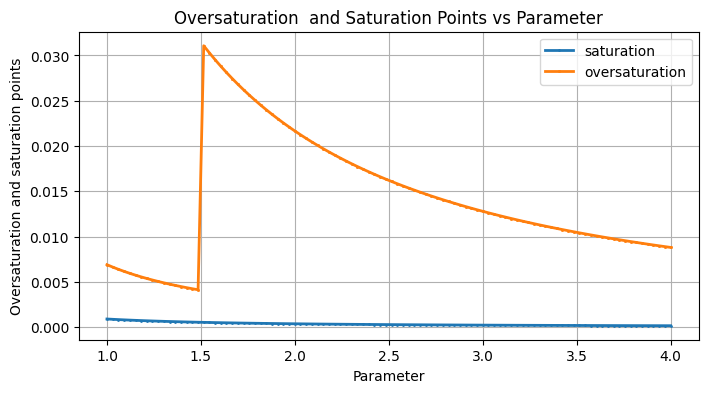

In [16]:
FUNTION_RUNNER('RADIUS', miauw, [], realspecies_withsols, True)

[13:20:22 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13')
[13:20:22 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[13:20:22 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2_g + 0.5 O2_g = 1.0 H2O_g',
 1: '0.5 O2_g + 1.0 CO_g = 1.0 CO2_g',
 2: '2.0 H2_g + 1.0 CO_g = 0.5 O2_g + 1.0 CH4_g'}
[13:20:22 - atmodeller.classes             - INFO     ] - Attempting to solve 10 model(s)


5.852746200000001e+24


[13:20:23 - atmodeller.classes             - INFO     ] - Solve complete: 10 (100.00%) successful model(s)
[13:20:23 - atmodeller.classes             - INFO     ] - Solver steps (max) = 144
[13:20:23 - atmodeller.output              - INFO     ] - Writing output to excel
[13:20:23 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[13:20:23 - atmodeller.output_core         - INFO     ] - Computing asdict output
[13:20:23 - atmodeller.output              - INFO     ] - Output written to FILE2.xlsx
[13:20:23 - atmodeller.output              - INFO     ] - Writing output to pickle
[13:20:23 - atmodeller.output              - INFO     ] - Output written to FILE2.pkl
[13:20:23 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'C

6.504120577131055e+24


[13:20:24 - atmodeller.classes             - INFO     ] - Solve complete: 10 (100.00%) successful model(s)
[13:20:24 - atmodeller.classes             - INFO     ] - Solver steps (max) = 173
[13:20:24 - atmodeller.output              - INFO     ] - Writing output to excel
[13:20:24 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[13:20:24 - atmodeller.output_core         - INFO     ] - Computing asdict output
[13:20:24 - atmodeller.output              - INFO     ] - Output written to FILE2.xlsx
[13:20:24 - atmodeller.output              - INFO     ] - Writing output to pickle
[13:20:24 - atmodeller.output              - INFO     ] - Output written to FILE2.pkl
[13:20:24 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'C

...

[13:21:43 - atmodeller.classes             - INFO     ] - Solve complete: 10 (100.00%) successful model(s)
[13:21:43 - atmodeller.classes             - INFO     ] - Solver steps (max) = 76
[13:21:43 - atmodeller.output              - INFO     ] - Writing output to excel
[13:21:43 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[13:21:43 - atmodeller.output_core         - INFO     ] - Computing asdict output
[13:21:43 - atmodeller.output              - INFO     ] - Output written to FILE2.xlsx
[13:21:43 - atmodeller.output              - INFO     ] - Writing output to pickle
[13:21:43 - atmodeller.output              - INFO     ] - Output written to FILE2.pkl
[13:21:43 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CH

7.641441965061479e+25


[13:21:43 - atmodeller.output              - INFO     ] - Writing output to excel
[13:21:43 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[13:21:43 - atmodeller.output_core         - INFO     ] - Computing asdict output
[13:21:44 - atmodeller.output              - INFO     ] - Output written to FILE2.xlsx
[13:21:44 - atmodeller.output              - INFO     ] - Writing output to pickle
[13:21:44 - atmodeller.output              - INFO     ] - Output written to FILE2.pkl
[13:21:44 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13')
[13:21:44 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[13:21:44 - atmodelle

7.727639453228033e+25


[13:21:44 - atmodeller.output              - INFO     ] - Output written to FILE2.xlsx
[13:21:44 - atmodeller.output              - INFO     ] - Writing output to pickle
[13:21:44 - atmodeller.output              - INFO     ] - Output written to FILE2.pkl


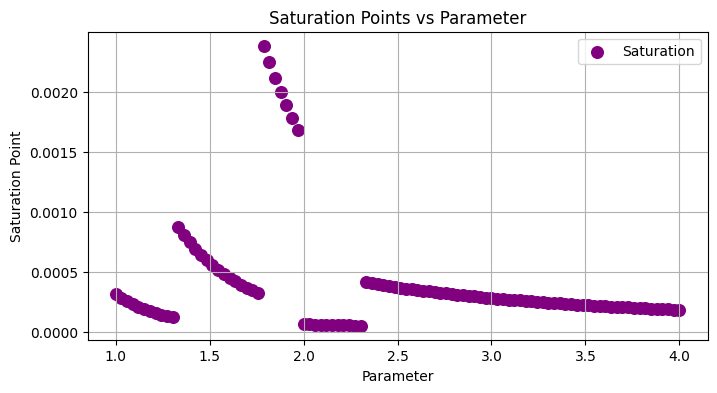

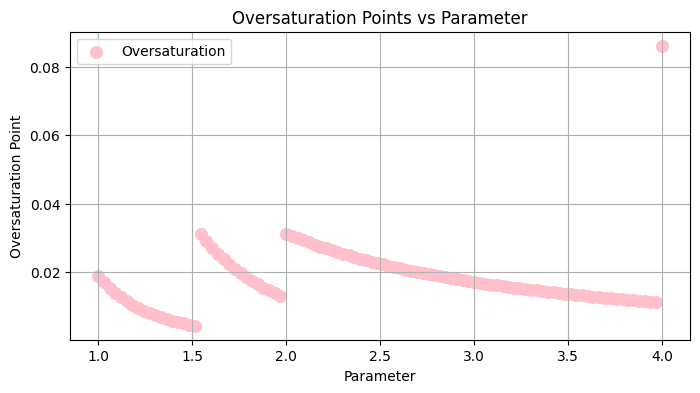

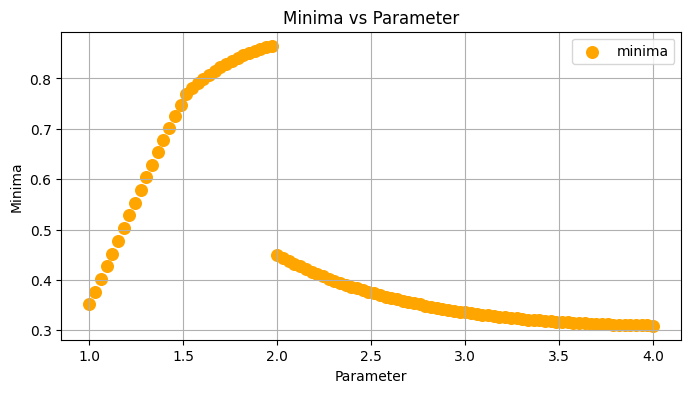

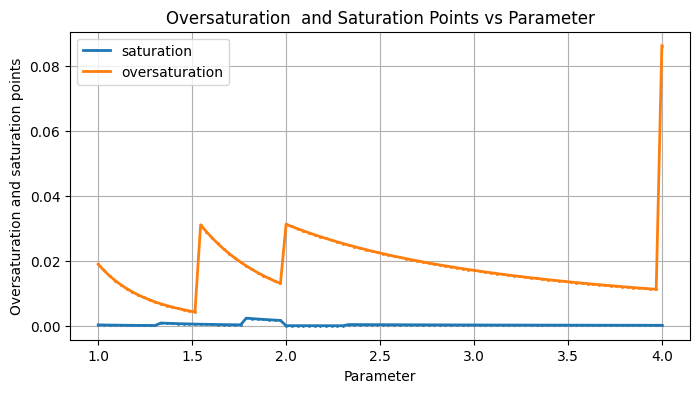

In [21]:
FUNTION_RUNNER('RADIUS', miauw, [], realspecies_withsols, True)